# 03b — AutoML v0.2: corrected grid search
**Owner:** Sharan Raj JANAKIRAMAN (M3)

**Why a v0.2.** The v0.1 grid search (notebook 03) avoided leakage, but its models were tuned on **different amounts of data** (logistic regression 100,000 people, trees 30,000, kNN 20,000, SVM 10,000) with tiny grids. That made the ranking unfair: "logistic regression is best" turned out to be an effect of sample size.

**What v0.2 changes** (`src/models/automl_v2.py`):
- logistic regression, decision tree and random forest tuned on the **same 100,000 people**; kNN and SVM (which scale badly) on the **same 20,000**;
- all five tuned models also scored on **one identical 20,000-person sample** (fair ranking);
- dense input for trees (much faster), wider grids, no iteration cap for SVM;
- best logistic regression, tree and forest retrained **out-of-fold on all 619,552 training people**.

Everything uses the training years 2019–2023 with 5 folds grouped by accident and PR-AUC. **The test years are not used.** The v0.1 files are kept because the M4 ensembles and the frozen final test were built on them; v0.2 does not replace any model already scored on 2024–2025.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
import matplotlib.pyplot as plt
from src.config import RESULTS_DIR, FIGURES_DIR
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
search = pd.read_csv(RESULTS_DIR / "automl_v02_search.csv")
best = json.loads((RESULTS_DIR / "automl_v02_best_params.json").read_text())
equal = pd.read_csv(RESULTS_DIR / "automl_v02_equal_sample.csv")
full2 = pd.read_csv(RESULTS_DIR / "automl_v02_full_train.csv")
full1 = pd.read_csv(RESULTS_DIR / "automl_v01_full_train.csv")
best1 = json.loads((RESULTS_DIR / "automl_v01_best_params.json").read_text())

## 1. Tuning results
Best setting of each model with its cross-validated PR-AUC (± std over the 5 folds) and its PR-AUC on the training folds (a large gap = overfitting).

In [2]:
tab = pd.DataFrame([{"model": m, "best settings": {k.replace("model__", ""): v for k, v in b["params"].items()},
                     "people": b["subsample_people"], "CV PR-AUC": round(b["cv_pr_auc_mean"], 4),
                     "± std": round(b["cv_pr_auc_std"], 4), "train PR-AUC": round(b["train_pr_auc_mean"], 4),
                     "search time (s)": b["search_time_s"]} for m, b in best.items()]).sort_values("CV PR-AUC", ascending=False)
display(tab)
print("Settings tested:", search.groupby("model").size().to_dict())

,model,best settings,people,CV PR-AUC,± std,train PR-AUC,search time (s)
2,Random forest,"{'max_depth': None, 'min_samples_leaf': 5}",99999,0.6044,0.0063,0.8016,795
0,Logistic regression,{'C': 0.1},99999,0.5897,0.0067,0.5988,60
4,SVM,{'C': 1},19998,0.5816,0.0098,0.7704,539
1,Decision tree,"{'max_depth': 18, 'min_samples_leaf': 100}",99999,0.5575,0.0037,0.6021,438
3,k-nearest neighbours,"{'n_neighbors': 25, 'weights': 'distance'}",19998,0.5396,0.0072,1.0000,352


Settings tested: {'Decision tree': 24, 'Logistic regression': 5, 'Random forest': 6, 'SVM': 3, 'k-nearest neighbours': 8}


## 2. Fair ranking: every tuned model on the same 20,000 people
Same people, same folds, same metric: the only difference between the bars is the model.

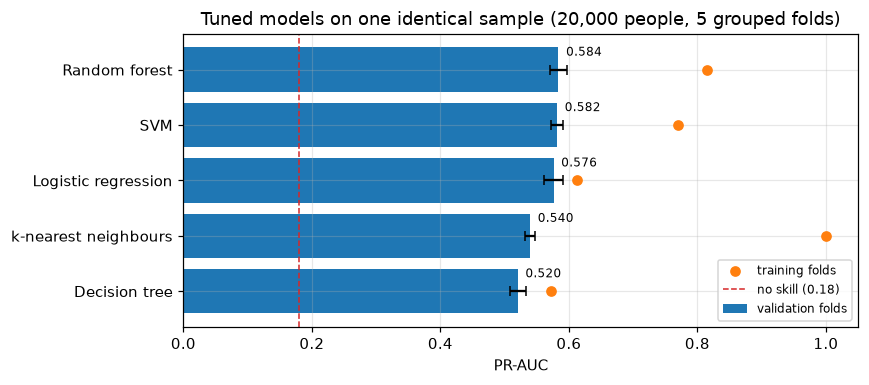

,model,cv_pr_auc_mean,cv_pr_auc_std,train_pr_auc_mean,people
2,Random forest,0.5837,0.0129,0.8147,19998
4,SVM,0.5816,0.0098,0.7704,19998
0,Logistic regression,0.5761,0.0142,0.6132,19998
3,k-nearest neighbours,0.5396,0.0072,1.0000,19998
1,Decision tree,0.5204,0.0121,0.5719,19998


In [3]:
e = equal.sort_values("cv_pr_auc_mean")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(e.model, e.cv_pr_auc_mean, xerr=e.cv_pr_auc_std, capsize=3, color="tab:blue", label="validation folds")
ax.scatter(e.train_pr_auc_mean, e.model, color="tab:orange", zorder=3, label="training folds")
ax.axvline(0.18, color="tab:red", ls="--", lw=1, label="no skill (0.18)")
for y_, v in enumerate(e.cv_pr_auc_mean):
    ax.text(v + 0.012, y_ + 0.25, f"{v:.3f}", fontsize=8)
ax.set(xlim=(0, 1.05), xlabel="PR-AUC", title="Tuned models on one identical sample (20,000 people, 5 grouped folds)")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "m3_v02_equal_sample.png"); plt.show()
display(equal.sort_values("cv_pr_auc_mean", ascending=False))

## 3. All training years: v0.1 settings vs v0.2 settings
Out-of-fold predictions on all 619,552 training people (each person predicted by a model that never saw their accident). v0.1 full-data numbers come from the M4 run (`automl_v01_full_train.csv`).

,model,settings v0.1,pr_auc v0.1,settings v0.2,pr_auc v0.2,gain
0,Logistic regression,{'C': 0.1},0.5889,{'C': 0.1},0.5888,-0.0001
1,Decision tree,"{'max_depth': 16, 'min_samples_leaf': 100}",0.5834,"{'max_depth': 18, 'min_samples_leaf': 100}",0.5843,0.0009
2,Random forest,"{'max_depth': None, 'min_samples_leaf': 1}",0.6140,"{'max_depth': None, 'min_samples_leaf': 5}",0.6211,0.0071


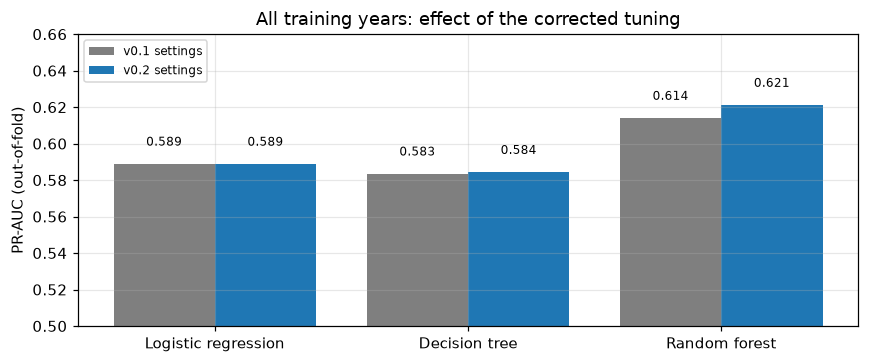

In [4]:
cmp = full1[["model", "pr_auc", "roc_auc", "recall", "precision", "f2"]].merge(
    full2[["model", "pr_auc", "roc_auc", "recall", "precision", "f2"]], on="model", suffixes=(" v0.1", " v0.2"))
cmp["settings v0.1"] = cmp.model.map(lambda m: {k.replace("model__", ""): v for k, v in best1[m]["params"].items()})
cmp["settings v0.2"] = cmp.model.map(lambda m: {k.replace("model__", ""): v for k, v in best[m]["params"].items()})
cmp["gain"] = cmp["pr_auc v0.2"] - cmp["pr_auc v0.1"]
display(cmp[["model", "settings v0.1", "pr_auc v0.1", "settings v0.2", "pr_auc v0.2", "gain"]].round(4))
fig, ax = plt.subplots(figsize=(8, 3.4))
x = range(len(cmp))
ax.bar([i - 0.2 for i in x], cmp["pr_auc v0.1"], width=0.4, color="tab:gray", label="v0.1 settings")
ax.bar([i + 0.2 for i in x], cmp["pr_auc v0.2"], width=0.4, color="tab:blue", label="v0.2 settings")
for i, (a, b) in enumerate(zip(cmp["pr_auc v0.1"], cmp["pr_auc v0.2"])):
    ax.text(i - 0.2, a + 0.01, f"{a:.3f}", ha="center", fontsize=8); ax.text(i + 0.2, b + 0.01, f"{b:.3f}", ha="center", fontsize=8)
ax.set_xticks(list(x)); ax.set_xticklabels(cmp.model)
ax.set(ylim=(0.5, 0.66), ylabel="PR-AUC (out-of-fold)", title="All training years: effect of the corrected tuning")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "m3_v01_vs_v02_full.png"); plt.show()

## 4. Findings
- **The v0.1 ranking was an artifact of sample size.** With identical data, the random forest beats logistic regression (0.584 vs 0.576 on the same 20,000 people; 0.604 vs 0.590 on the same 100,000).
- **On all training years, the corrected forest settings (no depth limit, leaf 5, 200 trees) reach PR-AUC 0.621**, against 0.614 with the v0.1 settings and 0.589 for logistic regression. The tree barely changes (0.583 → 0.584).
- **Flexible models gain from more data, linear models do not:** the tree goes from 0.530 (30k) to 0.558 (100k) to 0.584 (all data); logistic regression stays at 0.589–0.590.
- **Bias–variance:** the forest still fits its training folds much better (0.80 at 100k) than unseen accidents, but it is the best model on unseen folds, so the gap is accepted. kNN memorises completely (train 1.000) and generalises worst among flexible models.
- **Boosting and CatBoost (M4) remain better** (0.630 and 0.647 out-of-fold), so the final model choice does not change.
- **Limits:** kNN and SVM were tuned on 20,000 people only (their cost grows too fast); one subsample per size; CV score of a selected setting is slightly optimistic. No test years used.